# [EDA] 제공 데이터 전체 탐색 — 2026-09-22

- 작성자: 이정연 (`ljy`)
- 목적: SKT 유동인구와 신한카드 주제2 데이터의 품질을 확인하고 고립 신호 가설 후보를 도출한다.
- 관측 기간: 2025-07~2025-12
- 대상 지역: 서울 강남구, 강원 춘천시
- 분석 단위: 개인이 아닌 비식별 지역·인구집단 집계

## tl;dr

- SKT 18개 파일의 기간·스키마는 일치했고 기본 키와 값에 결측·음수는 없었다. 다만 2025년 12월 시간대 파일과 요일 파일은 모든 고유 행이 정확히 두 번씩 들어 있어 분석 시 완전 중복을 제거했다.
- `기준월 × 지역 × 성별 × 연령대` 공통 집계는 144행이며 키 중복과 핵심값 결측이 없다.
- 춘천시 60대 이상은 7월 대비 12월 유동인구가 4.18%, 결제건수가 5.78% 감소했고 지역 내 유동인구 비중도 0.76%p 낮아졌다. 계획한 이동·소비 동반 위축 후보에 해당하지만 업종 다양성은 성별에 따라 방향이 달라 세 영역의 일관된 위축으로 단정할 수 없다.
- 신한카드 고객 거주 시도 구성에서 춘천시 60대 이상은 남녀 모두 외지 결제건수 비중이 각각 2.43%p, 2.20%p 감소했고 거주 시도 다양성도 낮아졌다. 반면 강남구는 모든 성·연령 집단에서 외지 비중과 다양성이 증가해 지역별 방향이 달랐다.
- 같은 기간 행정안전부 통계에서 춘천시 1인세대 비율은 43.20%에서 43.46%로 0.26%p, 10대 이상 1인세대 중 60대 이상 비중은 40.74%에서 41.38%로 0.64%p 높아졌다. 이는 지역 취약성 배경지표이며 고립의 원인이나 결과를 뜻하지 않는다.
- 모든 결과는 개인의 고립 판정이 아니라 집단 수준의 의심 신호다. 6개월의 계절·날씨·인구구성 효과와 SKT 지역 추정 오차를 추가 검증해야 한다.

## Context & Methods

### Key Assumptions

- 신한카드는 본 프로젝트 부문에 해당하는 주제2 데이터셋2만 분석한다.
- SKT 좌표는 문서상 UTM-K(EPSG:5179)이지만 행정경계 공간 조인 전까지 지역을 확정하지 않는다.
- `BLOCK_CD` 앞자리로 행정구역을 추정하지 않는다.
- 6개월 관측만으로 장기 추세, 계절성 또는 인과관계를 주장하지 않는다.
- 대용량 신한카드 파일은 청크 단위로 읽어 메모리 사용을 제한한다.

In [1]:
from collections import Counter
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from folium.plugins import HeatMap
from pyproj import Transformer

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["font.family"] = "Apple SD Gothic Neo"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 50)

RANDOM_SEED = 42
CHUNK_SIZE = 200_000
EXPECTED_MONTHS = {f"2025{month:02d}" for month in range(7, 13)}
EXPECTED_REGIONS = {"서울 강남구", "강원 춘천시"}

## Data

### 1. 입력 파일 찾기

한글 파일명의 유니코드 정규화 차이를 피하기 위해 고정된 디렉터리 문자열 대신 파일 패턴으로 찾는다.

In [2]:
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data" / "raw").exists():
    REPO_ROOT = REPO_ROOT.parent

RAW_DIR = REPO_ROOT / "data" / "raw"
SK_FILES = sorted(RAW_DIR.rglob("flow_*_pop_*.csv"))
SHINHAN_TOPIC2_CANDIDATES = sorted(
    path for path in RAW_DIR.rglob("*.txt") if path.stem.endswith("2")
)

assert len(SK_FILES) == 18, f"SKT 파일 18개 예상, 실제 {len(SK_FILES)}개"
assert len(SHINHAN_TOPIC2_CANDIDATES) == 1, (
    f"신한카드 주제2 파일 1개 예상, 실제 {len(SHINHAN_TOPIC2_CANDIDATES)}개"
)
SHINHAN_TOPIC2_FILE = SHINHAN_TOPIC2_CANDIDATES[0]

inventory = pd.DataFrame(
    [
        {
            "source": "SKT",
            "file": path.name,
            "size_mb": path.stat().st_size / 1024**2,
        }
        for path in SK_FILES
    ]
    + [
        {
            "source": "신한카드 주제2",
            "file": SHINHAN_TOPIC2_FILE.name,
            "size_mb": SHINHAN_TOPIC2_FILE.stat().st_size / 1024**2,
        }
    ]
)
inventory.style.format({"size_mb": "{:.1f}"})

,source,file,size_mb
0,SKT,flow_age_pop_202507.csv,10.4
1,SKT,flow_age_pop_202508.csv,10.6
2,SKT,flow_age_pop_202509.csv,10.5
3,SKT,flow_age_pop_202510.csv,10.7
4,SKT,flow_age_pop_202511.csv,10.6
5,SKT,flow_age_pop_202512.csv,10.4
6,SKT,flow_time_pop_202507.csv,14.8
7,SKT,flow_time_pop_202508.csv,15.0
8,SKT,flow_time_pop_202509.csv,14.8
9,SKT,flow_time_pop_202510.csv,15.2


### 2. SKT 파일 단위 품질 점검

각 파일을 한 번씩 읽어 월, 기본 키, 좌표, 결측과 음수 값을 확인한다. 실제 CSV는 UTF-8 BOM으로 읽힌다.

In [3]:
SK_KEY_COLUMNS = ["STD_YM", "BLOCK_CD", "X_COORD", "Y_COORD"]


def audit_sk_file(path: Path) -> tuple[dict, tuple[str, ...]]:
    data = pd.read_csv(
        path,
        sep="|",
        encoding="utf-8-sig",
        dtype={"STD_YM": "string", "BLOCK_CD": "string"},
    )
    value_columns = [column for column in data.columns if column not in SK_KEY_COLUMNS]
    key_duplicate_extra = int(data.duplicated(SK_KEY_COLUMNS).sum())
    exact_duplicate_extra = int(data.duplicated().sum())
    max_key_frequency = int(data.groupby(SK_KEY_COLUMNS, dropna=False).size().max())
    expected_month = path.stem.rsplit("_", maxsplit=1)[-1]
    table = path.stem.removesuffix(f"_{expected_month}")

    result = {
        "file": path.name,
        "table": table,
        "expected_month": expected_month,
        "actual_months": ",".join(sorted(data["STD_YM"].dropna().unique())),
        "rows": len(data),
        "columns": len(data.columns),
        "unique_blocks": data["BLOCK_CD"].nunique(dropna=True),
        "duplicate_keys": key_duplicate_extra,
        "exact_duplicates": exact_duplicate_extra,
        "duplicate_keys_are_exact": key_duplicate_extra == exact_duplicate_extra,
        "max_key_frequency": max_key_frequency,
        "key_nulls": int(data[SK_KEY_COLUMNS].isna().sum().sum()),
        "value_nulls": int(data[value_columns].isna().sum().sum()),
        "negative_values": int(data[value_columns].lt(0).sum().sum()),
        "x_min": data["X_COORD"].min(),
        "x_max": data["X_COORD"].max(),
        "y_min": data["Y_COORD"].min(),
        "y_max": data["Y_COORD"].max(),
    }
    return result, tuple(data.columns)


sk_results = [audit_sk_file(path) for path in SK_FILES]
sk_audit = pd.DataFrame(result for result, _ in sk_results).sort_values(
    ["table", "expected_month"]
)
sk_schemas = {path.name: schema for path, (_, schema) in zip(SK_FILES, sk_results, strict=True)}
sk_audit

,file,table,expected_month,actual_months,rows,columns,unique_blocks,duplicate_keys,exact_duplicates,duplicate_keys_are_exact,max_key_frequency,key_nulls,value_nulls,negative_values,x_min,x_max,y_min,y_max
0,flow_age_pop_202507.csv,flow_age_pop,202507,202507,98129,16,2793,0,0,True,1,0,0,0,956633.991787,1.043384e+06,1.939779e+06,2.008279e+06
1,flow_age_pop_202508.csv,flow_age_pop,202508,202508,99115,16,2793,0,0,True,1,0,0,0,956633.991787,1.043384e+06,1.939779e+06,2.008279e+06
2,flow_age_pop_202509.csv,flow_age_pop,202509,202509,99469,16,2793,0,0,True,1,0,0,0,956633.991787,1.043384e+06,1.939779e+06,2.008279e+06
3,flow_age_pop_202510.csv,flow_age_pop,202510,202510,100750,16,2793,0,0,True,1,0,0,0,956633.991787,1.046134e+06,1.939779e+06,2.008279e+06
4,flow_age_pop_202511.csv,flow_age_pop,202511,202511,100444,16,2793,0,0,True,1,0,0,0,956583.991787,1.043384e+06,1.939779e+06,2.008279e+06
5,flow_age_pop_202512.csv,flow_age_pop,202512,202512,98345,16,2793,0,0,True,1,0,0,0,956583.991787,1.043384e+06,1.939779e+06,2.008279e+06
6,flow_time_pop_202507.csv,flow_time_pop,202507,202507,94099,28,2792,0,0,True,1,0,0,0,956633.991787,1.043384e+06,1.939779e+06,2.008279e+06
7,flow_time_pop_202508.csv,flow_time_pop,202508,202508,95374,28,2792,0,0,True,1,0,0,0,956633.991787,1.043384e+06,1.939779e+06,2.008279e+06
8,flow_time_pop_202509.csv,flow_time_pop,202509,202509,95084,28,2792,0,0,True,1,0,0,0,956633.991787,1.043384e+06,1.939779e+06,2.008279e+06
9,flow_time_pop_202510.csv,flow_time_pop,202510,202510,97881,28,2793,0,0,True,1,0,0,0,956633.991787,1.043384e+06,1.939779e+06,2.008279e+06


In [4]:
sk_checks = pd.Series(
    {
        "expected_months_present": set(sk_audit["expected_month"]) == EXPECTED_MONTHS,
        "file_months_match": sk_audit.eval("expected_month == actual_months").all(),
        "no_duplicate_keys": sk_audit["duplicate_keys"].eq(0).all(),
        "duplicate_keys_match_exact_rows": sk_audit.eval(
            "duplicate_keys == exact_duplicates"
        ).all(),
        "duplicates_isolated_to_202512_time_weekday": set(
            sk_audit.loc[sk_audit["duplicate_keys"].gt(0), "file"]
        )
        == {"flow_time_pop_202512.csv", "flow_wkdy_pop_202512.csv"},
        "duplicate_key_frequency_at_most_two": sk_audit["max_key_frequency"].le(2).all(),
        "no_key_nulls": sk_audit["key_nulls"].eq(0).all(),
        "no_negative_values": sk_audit["negative_values"].eq(0).all(),
        "one_schema_per_table": all(
            len(
                {
                    schema
                    for file_name, schema in sk_schemas.items()
                    if file_name.startswith(table)
                }
            )
            == 1
            for table in sk_audit["table"].unique()
        ),
    },
    name="passed",
)
sk_checks.to_frame()

,passed
expected_months_present,True
file_months_match,True
no_duplicate_keys,False
duplicate_keys_match_exact_rows,True
duplicates_isolated_to_202512_time_weekday,True
duplicate_key_frequency_at_most_two,True
no_key_nulls,True
no_negative_values,True
one_schema_per_table,True


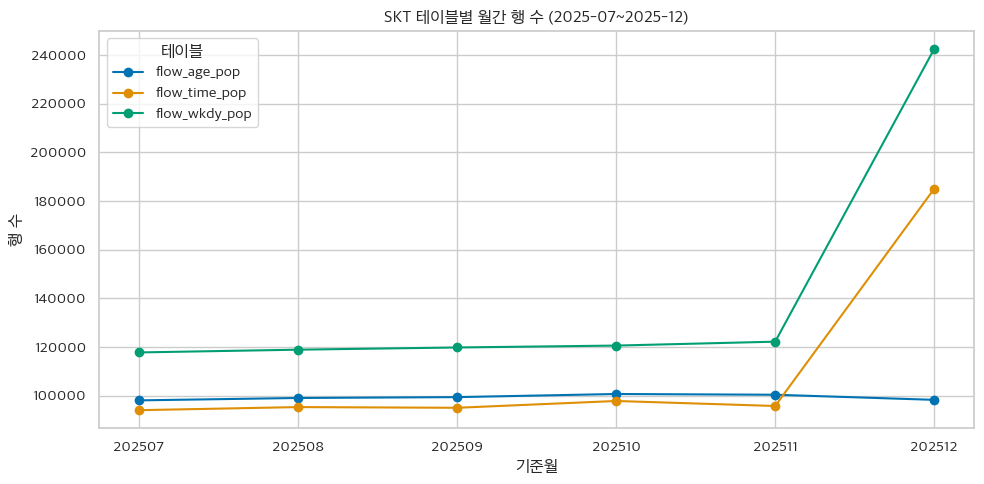

In [5]:
sk_monthly_rows = sk_audit.pivot(index="expected_month", columns="table", values="rows")
ax = sk_monthly_rows.plot(marker="o", figsize=(10, 5))
ax.set(
    title="SKT 테이블별 월간 행 수 (2025-07~2025-12)",
    xlabel="기준월",
    ylabel="행 수",
)
ax.legend(title="테이블")
plt.tight_layout()
plt.show()

### 3. 신한카드 주제2 청크 단위 품질 점검

전체 파일을 청크 단위로 한 번 스캔해 기간, 지역, 범주, 결측과 숫자 변환 오류를 집계한다. 결측과 원본의 `정보없음` 값은 구분한다.

In [6]:
SHINHAN_COLUMNS = [
    "TA_YMD",
    "MCT_SGG_CD",
    "MCT_RY_CD",
    "CLN_SGG_CD",
    "SEX_CCD",
    "AGE_CCD",
    "TS_AT",
    "USE_CNT",
]
CATEGORY_COLUMNS = ["MCT_SGG_CD", "MCT_RY_CD", "CLN_SGG_CD", "SEX_CCD", "AGE_CCD"]
NUMERIC_COLUMNS = ["TS_AT", "USE_CNT"]

row_count = 0
null_counts = Counter()
numeric_failures = Counter()
negative_counts = Counter()
zero_counts = Counter()
region_metric_totals = {column: Counter() for column in NUMERIC_COLUMNS}
category_values = {column: set() for column in CATEGORY_COLUMNS}
monthly_region_counts = Counter()
date_min = None
date_max = None

for chunk in pd.read_csv(
    SHINHAN_TOPIC2_FILE,
    sep="\t",
    encoding="cp949",
    dtype="string",
    chunksize=CHUNK_SIZE,
):
    assert list(chunk.columns) == SHINHAN_COLUMNS
    row_count += len(chunk)
    null_counts.update(chunk.isna().sum().to_dict())

    chunk_date_min = chunk["TA_YMD"].min()
    chunk_date_max = chunk["TA_YMD"].max()
    date_min = chunk_date_min if date_min is None else min(date_min, chunk_date_min)
    date_max = chunk_date_max if date_max is None else max(date_max, chunk_date_max)

    for column in CATEGORY_COLUMNS:
        category_values[column].update(chunk[column].dropna().unique())

    for column in NUMERIC_COLUMNS:
        numeric = pd.to_numeric(chunk[column], errors="coerce")
        numeric_failures[column] += int((chunk[column].notna() & numeric.isna()).sum())
        negative_counts[column] += int(numeric.lt(0).sum())
        zero_counts[column] += int(numeric.eq(0).sum())
        region_metric_totals[column].update(
            numeric.groupby(chunk["MCT_SGG_CD"]).sum().to_dict()
        )

    counts = chunk.assign(TA_YM=chunk["TA_YMD"].str.slice(0, 6)).groupby(
        ["TA_YM", "MCT_SGG_CD"], dropna=False
    ).size()
    monthly_region_counts.update(counts.to_dict())

shinhan_audit = pd.DataFrame(
    {
        "metric": [
            "rows",
            "date_min",
            "date_max",
            "TS_AT_numeric_failures",
            "USE_CNT_numeric_failures",
            "TS_AT_negative",
            "USE_CNT_negative",
            "TS_AT_zero",
            "USE_CNT_zero",
        ],
        "value": [
            row_count,
            date_min,
            date_max,
            numeric_failures["TS_AT"],
            numeric_failures["USE_CNT"],
            negative_counts["TS_AT"],
            negative_counts["USE_CNT"],
            zero_counts["TS_AT"],
            zero_counts["USE_CNT"],
        ],
    }
)
shinhan_audit

,metric,value
0,rows,1806800
1,date_min,20250701
2,date_max,20251231
3,TS_AT_numeric_failures,0
4,USE_CNT_numeric_failures,0
5,TS_AT_negative,0
6,USE_CNT_negative,0
7,TS_AT_zero,0
8,USE_CNT_zero,0


In [7]:
shinhan_categories = pd.DataFrame(
    [
        {
            "column": column,
            "unique_count": len(values),
            "values": ", ".join(sorted(values)) if len(values) <= 20 else "20개 초과",
            "null_count": null_counts[column],
        }
        for column, values in category_values.items()
    ]
)
shinhan_categories

,column,unique_count,values,null_count
0,MCT_SGG_CD,2,"강원 춘천시, 서울 강남구",0
1,MCT_RY_CD,90,20개 초과,0
2,CLN_SGG_CD,17,"강원, 경기, 경남, 경북, 대구, 대전, 부산, 서울, 세종, 울산, 인천, 전남...",0
3,SEX_CCD,2,"남성, 여성",0
4,AGE_CCD,9,"10 대, 20 대, 30 대, 40 대, 50 대, 60 대, 70 대, 80 대...",0


In [8]:
shinhan_checks = pd.Series(
    {
        "date_range_valid": date_min == "20250701" and date_max == "20251231",
        "regions_valid": category_values["MCT_SGG_CD"] == EXPECTED_REGIONS,
        "no_corporate_sex": "법인" not in category_values["SEX_CCD"],
        "no_corporate_age": "법인" not in category_values["AGE_CCD"],
        "numeric_conversion_valid": sum(numeric_failures.values()) == 0,
        "no_negative_metrics": sum(negative_counts.values()) == 0,
    },
    name="passed",
)
shinhan_checks.to_frame()

,passed
date_range_valid,True
regions_valid,True
no_corporate_sex,True
no_corporate_age,True
numeric_conversion_valid,True
no_negative_metrics,True


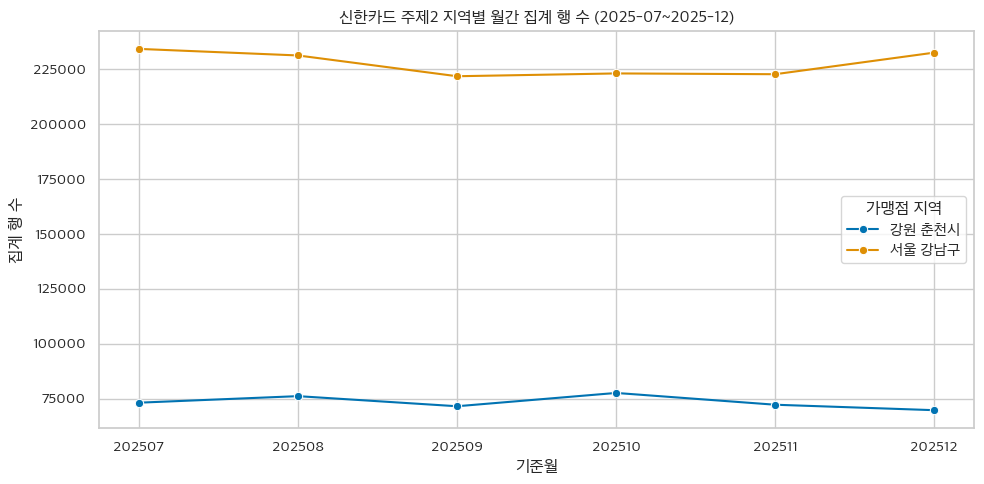

In [9]:
monthly_region_rows = (
    pd.Series(monthly_region_counts, name="rows")
    .rename_axis(["TA_YM", "MCT_SGG_CD"])
    .reset_index()
)
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=monthly_region_rows,
    x="TA_YM",
    y="rows",
    hue="MCT_SGG_CD",
    marker="o",
    ax=ax,
)
ax.set(
    title="신한카드 주제2 지역별 월간 집계 행 수 (2025-07~2025-12)",
    xlabel="기준월",
    ylabel="집계 행 수",
)
ax.legend(title="가맹점 지역")
plt.tight_layout()
plt.show()

### 4. 두 데이터의 공간 분포 지도

SKT는 실제 격자 좌표를 표시한다. 신한카드는 시군구보다 세밀한 위치가 없으므로 지역별 결제건수를 해당 SKT 좌표 군집의 중심에 하나의 버블로 표시한다. 행정경계 파일이 없는 상태이므로 이 지도는 분포 확인용이며 경계 판정 결과가 아니다.

In [10]:
sk_coordinates = pd.concat(
    [
        pd.read_csv(
            path,
            sep="|",
            encoding="utf-8-sig",
            usecols=["X_COORD", "Y_COORD"],
        )
        for path in SK_FILES
    ],
    ignore_index=True,
).drop_duplicates()

transformer = Transformer.from_crs(5179, 4326, always_xy=True)
longitude, latitude = transformer.transform(
    sk_coordinates["X_COORD"].to_numpy(),
    sk_coordinates["Y_COORD"].to_numpy(),
)
sk_coordinates = sk_coordinates.assign(longitude=longitude, latitude=latitude)

sorted_longitude = np.sort(sk_coordinates["longitude"].unique())
largest_gap_index = int(np.diff(sorted_longitude).argmax())
longitude_cutoff = sorted_longitude[largest_gap_index : largest_gap_index + 2].mean()
sk_coordinates["region_inferred"] = np.where(
    sk_coordinates["longitude"] < longitude_cutoff,
    "서울 강남구",
    "강원 춘천시",
)

region_centers = (
    sk_coordinates.groupby("region_inferred", as_index=False)[["longitude", "latitude"]]
    .median()
    .rename(columns={"region_inferred": "region"})
)
card_region_summary = pd.DataFrame(
    {
        "region": sorted(EXPECTED_REGIONS),
        "TS_AT": [region_metric_totals["TS_AT"][region] for region in sorted(EXPECTED_REGIONS)],
        "USE_CNT": [
            region_metric_totals["USE_CNT"][region] for region in sorted(EXPECTED_REGIONS)
        ],
    }
).merge(region_centers, on="region", validate="one_to_one")

assert set(sk_coordinates["region_inferred"]) == EXPECTED_REGIONS
card_region_summary

,region,TS_AT,USE_CNT,longitude,latitude
0,강원 춘천시,2061142149283,50905195,127.724837,37.865337
1,서울 강남구,28089942678769,520928789,127.058552,37.494685


### 5. 실제 배경지도에서 확인

OpenStreetMap 배경지도 위에 SKT 격자 밀도와 신한카드 지역 집계를 겹친다. 브라우저 성능을 위해 SKT 좌표는 지역별 최대 15,000개를 고정 난수로 표본화하며, 신한카드 합계는 전체 데이터를 사용한다.

In [11]:
region_colors = {"서울 강남구": "#0072B2", "강원 춘천시": "#E69F00"}
map_center = [sk_coordinates["latitude"].mean(), sk_coordinates["longitude"].mean()]
data_map = folium.Map(location=map_center, zoom_start=9, tiles="OpenStreetMap")

heatmap_gradients = {
    "서울 강남구": {0.2: "#56B4E9", 0.6: "#0072B2", 1.0: "#002B5B"},
    "강원 춘천시": {0.2: "#F0E442", 0.6: "#E69F00", 1.0: "#8C510A"},
}
for region, group in sk_coordinates.groupby("region_inferred"):
    sampled = group.sample(n=min(15_000, len(group)), random_state=RANDOM_SEED)
    HeatMap(
        sampled[["latitude", "longitude"]].to_numpy().tolist(),
        name=f"SKT 격자 밀도 — {region}",
        radius=6,
        blur=5,
        min_opacity=0.25,
        gradient=heatmap_gradients[region],
        show=True,
    ).add_to(data_map)

card_layer = folium.FeatureGroup(name="신한카드 지역별 결제건수", show=True)
for row in card_region_summary.itertuples(index=False):
    radius = 14 + 18 * (row.USE_CNT / card_region_summary["USE_CNT"].max()) ** 0.5
    popup = (
        f"<strong>{row.region}</strong><br>"
        f"결제건수 합계: {row.USE_CNT:,.0f}<br>"
        f"결제금액 합계: {row.TS_AT:,.0f}원<br>"
        "위치: 해당 지역 SKT 격자 좌표의 중앙값"
    )
    folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=radius,
        color=region_colors[row.region],
        fill=True,
        fill_color=region_colors[row.region],
        fill_opacity=0.75,
        weight=2,
        tooltip=f"신한카드 — {row.region}",
        popup=folium.Popup(popup, max_width=320),
    ).add_to(card_layer)
card_layer.add_to(data_map)

bounds = [
    [sk_coordinates["latitude"].min(), sk_coordinates["longitude"].min()],
    [sk_coordinates["latitude"].max(), sk_coordinates["longitude"].max()],
]
data_map.fit_bounds(bounds, padding=(20, 20))
folium.LayerControl(collapsed=False).add_to(data_map)
data_map

지도 사용법: 우측 상단 레이어 목록에서 강남구·춘천시 SKT 밀도층과 신한카드 버블을 각각 켜고 끌 수 있다. 버블을 누르면 지역별 전체 결제건수와 결제금액을 확인할 수 있다. 배경 타일을 표시하려면 인터넷 연결이 필요하다.

## Results

### 6. 공통 성·연령 분석 단위

두 제공 데이터를 `기준월 × 지역 × 성별 × 연령대`로 맞춘다. 신한카드의 60~90대는 SKT의 `60대 이상`으로 합산한다. 이 키는 같은 개인을 연결하는 조인 키가 아니라 집단별 분포와 변화 방향을 비교하기 위한 단위다.

SKT 지역명은 공식 제공 범위가 강남구·춘천시 두 곳이라는 조건에서 앞서 확인한 두 좌표 군집의 최대 경도 간격으로 임시 분류했다. 공식 행정경계 공간조인 전까지 추정값이다.

In [12]:
PROCESSED_DIR = REPO_ROOT / "data" / "processed"
SK_SEGMENT_FILE = PROCESSED_DIR / "sk_월지역성연령_집계.csv"
CARD_SEGMENT_FILE = PROCESSED_DIR / "shinhan_월지역성연령_집계.csv"

assert SK_SEGMENT_FILE.exists(), f"공통 집계 파일 필요: {SK_SEGMENT_FILE}"
assert CARD_SEGMENT_FILE.exists(), f"공통 집계 파일 필요: {CARD_SEGMENT_FILE}"

segment_keys = ["기준월", "지역", "성별", "연령대"]
segment_order = ["10대", "20대", "30대", "40대", "50대", "60대 이상"]

sk_segment = pd.read_csv(SK_SEGMENT_FILE, dtype={"기준월": "string"})
card_segment = pd.read_csv(CARD_SEGMENT_FILE, dtype={"기준월": "string"})
segment = sk_segment.merge(card_segment, on=segment_keys, validate="one_to_one")
segment["건당결제금액"] = segment["결제금액"] / segment["결제건수"]

for metric in ["일평균유동인구", "결제건수", "결제금액"]:
    segment[f"{metric}_지역내비중"] = segment[metric] / segment.groupby(
        ["기준월", "지역"]
    )[metric].transform("sum")
    segment[f"{metric}_전월증감률"] = segment.groupby(
        ["지역", "성별", "연령대"]
    )[metric].pct_change()
    segment[f"{metric}_7월지수"] = 100 * segment[metric] / segment.groupby(
        ["지역", "성별", "연령대"]
    )[metric].transform("first")

assert len(segment) == 144
assert not segment.duplicated(segment_keys).any()
assert not segment[[*segment_keys, "일평균유동인구", "결제금액", "결제건수"]].isna().any().any()

pd.Series(
    {
        "행 수": len(segment),
        "키 중복": int(segment.duplicated(segment_keys).sum()),
        "핵심값 결측": int(
            segment[["일평균유동인구", "결제금액", "결제건수"]].isna().sum().sum()
        ),
        "기간": f"{segment['기준월'].min()}~{segment['기준월'].max()}",
    },
    name="공통 집계 검증",
)

행 수                 144
키 중복                  0
핵심값 결측                0
기간        202507~202512
Name: 공통 집계 검증, dtype: object

### 7. 인구계층 구성과 활동 변화

절대 규모 차이의 영향을 줄이기 위해 지역·월별 전체 유동인구에서 각 성·연령 집단이 차지하는 비중과 7월 대비 지수를 함께 본다.

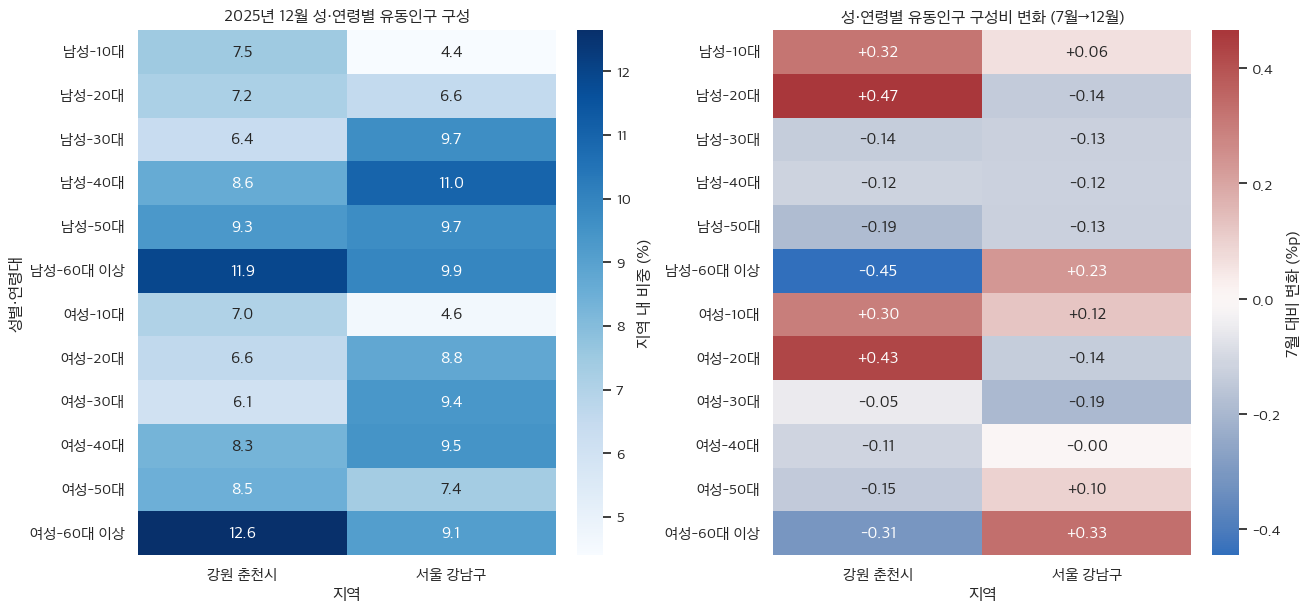

기준월                  202507     202512  7월대비변화율(%)
지역     성별 연령대                                     
서울 강남구 남성 20대     505487.62  480395.07       -4.96
       여성 30대     722767.30  687390.51       -4.89
강원 춘천시 남성 60대 이상  222021.18  211392.07       -4.79
서울 강남구 여성 20대     672178.71  642359.66       -4.44
       남성 30대     739930.75  708799.24       -4.21
          50대     742610.22  711397.79       -4.20
          40대     837871.25  804323.09       -4.00
강원 춘천시 여성 60대 이상  232767.09  224397.09       -3.60

In [13]:
composition = segment.pivot_table(
    index=["성별", "연령대"],
    columns=["지역", "기준월"],
    values="일평균유동인구_지역내비중",
)
composition_change = pd.DataFrame(
    {
        region: 100 * (composition[(region, "202512")] - composition[(region, "202507")])
        for region in sorted(EXPECTED_REGIONS)
    }
).reindex(pd.MultiIndex.from_product([["남성", "여성"], segment_order]))

fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
sns.heatmap(
    100 * composition.xs("202512", axis=1, level="기준월"),
    annot=True,
    fmt=".1f",
    cmap="Blues",
    cbar_kws={"label": "지역 내 비중 (%)"},
    ax=axes[0],
)
axes[0].set_title("2025년 12월 성·연령별 유동인구 구성")
axes[0].set_xlabel("지역")
axes[0].set_ylabel("성별·연령대")
sns.heatmap(
    composition_change,
    annot=True,
    fmt="+.2f",
    center=0,
    cmap="vlag",
    cbar_kws={"label": "7월 대비 변화 (%p)"},
    ax=axes[1],
)
axes[1].set_title("성·연령별 유동인구 구성비 변화 (7월→12월)")
axes[1].set_xlabel("지역")
axes[1].set_ylabel("")
plt.show()

flow_change = (
    segment.pivot_table(
        index=["지역", "성별", "연령대"], columns="기준월", values="일평균유동인구"
    )
    .assign(**{"7월대비변화율(%)": lambda x: 100 * (x["202512"] / x["202507"] - 1)})
    .sort_values("7월대비변화율(%)")
)
flow_change[["202507", "202512", "7월대비변화율(%)"]].head(8).round(2)

### 8. 소비활동 변화

`USE_CNT`는 이용자 수가 아니라 결제건수다. 결제건수·결제금액·건당 결제금액을 함께 비교하고, 한 지표의 감소를 곧바로 이용자 감소로 해석하지 않는다.

10대는 다른 연령대보다 절대 결제건수가 작아 7월 기준 지수가 크게 변동할 수 있으므로 절대 건수와 함께 해석한다.

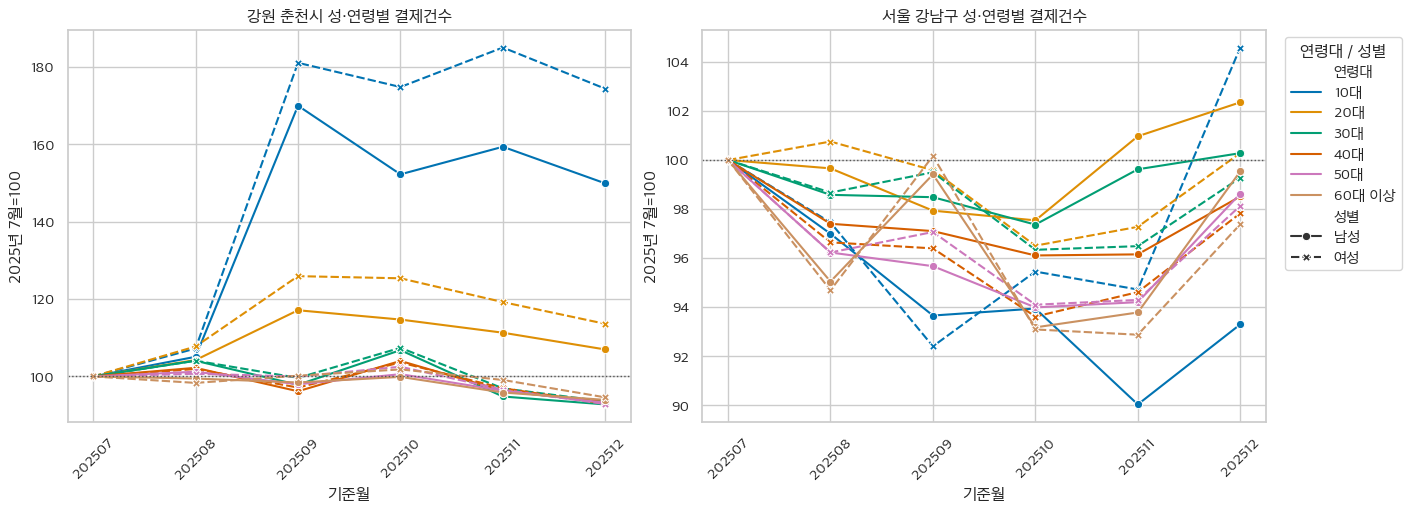

결제건수_7월대비(%)  결제금액_7월대비(%)  건당금액_7월대비(%)
지역     성별 연령대                                             
강원 춘천시 남성 30대            -7.23         -3.28          4.26
       여성 50대            -7.13         -1.01          6.60
          40대            -7.01         -2.08          5.30
       남성 50대            -6.79         -0.48          6.78
서울 강남구 남성 10대            -6.70          8.92         16.74
강원 춘천시 남성 40대            -6.67         -1.16          5.91
       여성 30대            -6.48          2.03          9.10
       남성 60대 이상         -6.06          1.78          8.35

In [14]:
card_change = (
    segment.pivot_table(
        index=["지역", "성별", "연령대"],
        columns="기준월",
        values=["결제건수", "결제금액", "건당결제금액"],
    )
)
card_change_summary = pd.DataFrame(
    {
        "결제건수_7월대비(%)": 100
        * (card_change[("결제건수", "202512")] / card_change[("결제건수", "202507")] - 1),
        "결제금액_7월대비(%)": 100
        * (card_change[("결제금액", "202512")] / card_change[("결제금액", "202507")] - 1),
        "건당금액_7월대비(%)": 100
        * (
            card_change[("건당결제금액", "202512")]
            / card_change[("건당결제금액", "202507")]
            - 1
        ),
    }
).sort_values("결제건수_7월대비(%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False, constrained_layout=True)
for ax, region in zip(axes, sorted(EXPECTED_REGIONS), strict=True):
    plot_data = segment[segment["지역"] == region]
    sns.lineplot(
        data=plot_data,
        x="기준월",
        y="결제건수_7월지수",
        hue="연령대",
        style="성별",
        hue_order=segment_order,
        markers=True,
        dashes=True,
        ax=ax,
    )
    ax.axhline(100, color="#555555", linewidth=1, linestyle=":")
    ax.set(title=f"{region} 성·연령별 결제건수", xlabel="기준월", ylabel="2025년 7월=100")
    ax.tick_params(axis="x", rotation=45)
    if ax is not axes[-1]:
        ax.get_legend().remove()
axes[-1].legend(title="연령대 / 성별", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

card_change_summary.head(8).round(2)

### 9. 소비 업종 다양성

월·지역·성·연령 집단별로 이용 업종 수, 상위 1개·3개 업종의 결제건수 집중도, 정규화 Shannon 다양성 지수를 계산한다. 이는 개인의 활동 반경이 아니라 집단의 업종 구성이다.

In [15]:
age_map = {
    "10대": "10대",
    "20대": "20대",
    "30대": "30대",
    "40대": "40대",
    "50대": "50대",
    "60대": "60대 이상",
    "70대": "60대 이상",
    "80대": "60대 이상",
    "90대": "60대 이상",
}
industry_parts = []
residence_parts = []

for chunk in pd.read_csv(
    SHINHAN_TOPIC2_FILE,
    sep="	",
    encoding="cp949",
    dtype="string",
    chunksize=CHUNK_SIZE,
):
    chunk = chunk.assign(
        기준월=chunk["TA_YMD"].str[:6],
        연령대=chunk["AGE_CCD"].str.replace(" ", "", regex=False).map(age_map),
        결제건수=pd.to_numeric(chunk["USE_CNT"]),
        결제금액=pd.to_numeric(chunk["TS_AT"]),
    )
    industry_parts.append(
        chunk.groupby(
            ["기준월", "MCT_SGG_CD", "SEX_CCD", "연령대", "MCT_RY_CD"],
            as_index=False,
            observed=True,
        )["결제건수"].sum()
    )
    residence_parts.append(
        chunk.groupby(
            ["기준월", "MCT_SGG_CD", "SEX_CCD", "연령대", "CLN_SGG_CD"],
            as_index=False,
            observed=True,
            dropna=False,
        )[["결제건수", "결제금액"]].sum()
    )

industry = (
    pd.concat(industry_parts, ignore_index=True)
    .groupby(
        ["기준월", "MCT_SGG_CD", "SEX_CCD", "연령대", "MCT_RY_CD"],
        as_index=False,
        observed=True,
    )["결제건수"]
    .sum()
    .rename(columns={"MCT_SGG_CD": "지역", "SEX_CCD": "성별", "MCT_RY_CD": "업종"})
)
industry["업종비중"] = industry["결제건수"] / industry.groupby(segment_keys)[
    "결제건수"
].transform("sum")
industry["entropy_part"] = -industry["업종비중"] * np.log(industry["업종비중"])
industry["비중순위"] = industry.groupby(segment_keys)["업종비중"].rank(
    method="first", ascending=False
)

diversity = industry.groupby(segment_keys, as_index=False).agg(
    이용업종수=("업종", "nunique"),
    상위1업종비중=("업종비중", "max"),
    Shannon=("entropy_part", "sum"),
)
top3 = (
    industry[industry["비중순위"] <= 3]
    .groupby(segment_keys, as_index=False)["업종비중"]
    .sum()
    .rename(columns={"업종비중": "상위3업종비중"})
)
diversity = diversity.merge(top3, on=segment_keys, validate="one_to_one")
diversity["업종다양성지수"] = diversity["Shannon"] / np.log(diversity["이용업종수"])
diversity["업종다양성_전월증감"] = diversity.groupby(
    ["지역", "성별", "연령대"]
)["업종다양성지수"].diff()

assert len(diversity) == 144
assert diversity["업종다양성지수"].between(0, 1).all()
diversity.head()

,기준월,지역,성별,연령대,이용업종수,상위1업종비중,Shannon,상위3업종비중,업종다양성지수,업종다양성_전월증감
0,202507,강원 춘천시,남성,10대,54,0.387769,2.377194,0.565207,0.59594,<NA>
1,202507,강원 춘천시,남성,20대,77,0.363111,2.54735,0.533911,0.586433,<NA>
2,202507,강원 춘천시,남성,30대,79,0.295906,2.746369,0.495745,0.628539,<NA>
3,202507,강원 춘천시,남성,40대,82,0.245076,2.843804,0.492145,0.645334,<NA>
4,202507,강원 춘천시,남성,50대,82,0.221248,2.825339,0.503382,0.641143,<NA>


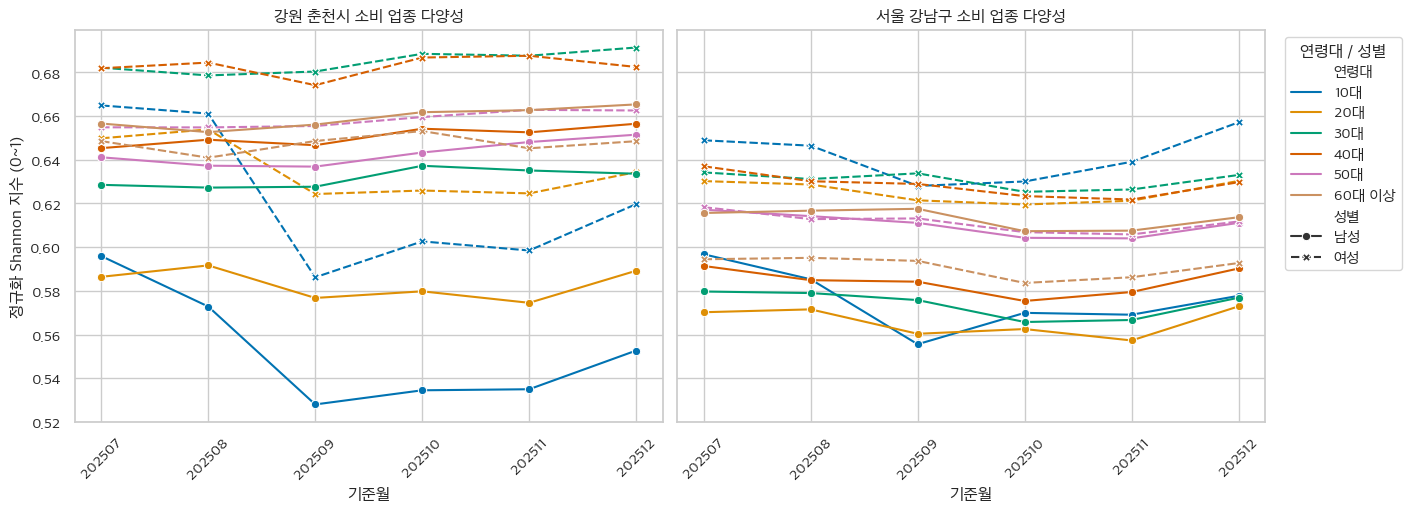

기준월            202507  202512  7월대비변화
지역     성별 연령대                        
강원 춘천시 여성 10대  0.6649  0.6197 -0.0452
       남성 10대  0.5959  0.5527 -0.0433
서울 강남구 남성 10대  0.5968  0.5777  -0.019
강원 춘천시 여성 20대  0.6498  0.6344 -0.0155
서울 강남구 여성 40대   0.637  0.6297 -0.0073
          50대  0.6183  0.6118 -0.0065
       남성 50대  0.6172  0.6111  -0.006
          30대  0.5797  0.5769 -0.0028

In [16]:
diversity_change = diversity.pivot_table(
    index=["지역", "성별", "연령대"], columns="기준월", values="업종다양성지수"
)
diversity_change["7월대비변화"] = diversity_change["202512"] - diversity_change["202507"]
diversity_change = diversity_change.sort_values("7월대비변화")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True, constrained_layout=True)
for ax, region in zip(axes, sorted(EXPECTED_REGIONS), strict=True):
    sns.lineplot(
        data=diversity[diversity["지역"] == region],
        x="기준월",
        y="업종다양성지수",
        hue="연령대",
        style="성별",
        hue_order=segment_order,
        markers=True,
        dashes=True,
        ax=ax,
    )
    ax.set(title=f"{region} 소비 업종 다양성", xlabel="기준월", ylabel="정규화 Shannon 지수 (0~1)")
    ax.tick_params(axis="x", rotation=45)
    if ax is not axes[-1]:
        ax.get_legend().remove()
axes[-1].legend(title="연령대 / 성별", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

diversity_change[["202507", "202512", "7월대비변화"]].head(8).round(4)

### 10. 이동·소비·다양성 동반 신호

세 지표를 같은 집단 키에서 비교한다. 아래 표는 탐색 우선순위를 정하기 위한 관측 요약이며 고립 위험 점수나 판정 결과가 아니다.

In [17]:
combined = segment.merge(
    diversity[[*segment_keys, "업종다양성지수", "업종다양성_전월증감"]],
    on=segment_keys,
    validate="one_to_one",
)
combined["이동소비동반감소"] = (
    combined["일평균유동인구_전월증감률"].lt(0)
    & combined["결제건수_전월증감률"].lt(0)
)
combined["2개월연속동반감소"] = combined.groupby(
    ["지역", "성별", "연령대"]
)["이동소비동반감소"].transform(lambda values: values.rolling(2).sum().ge(2))

first_last = combined[combined["기준월"].isin(["202507", "202512"])].pivot_table(
    index=["지역", "성별", "연령대"],
    columns="기준월",
    values=["일평균유동인구", "결제건수", "업종다양성지수"],
)
signal_summary = pd.DataFrame(
    {
        "유동인구_7월대비(%)": 100
        * (first_last[("일평균유동인구", "202512")] / first_last[("일평균유동인구", "202507")] - 1),
        "결제건수_7월대비(%)": 100
        * (first_last[("결제건수", "202512")] / first_last[("결제건수", "202507")] - 1),
        "다양성_7월대비": first_last[("업종다양성지수", "202512")]
        - first_last[("업종다양성지수", "202507")],
        "동반감소월수": combined.groupby(["지역", "성별", "연령대"])[
            "이동소비동반감소"
        ].sum(),
        "2개월연속동반감소": combined.groupby(["지역", "성별", "연령대"])[
            "2개월연속동반감소"
        ].any(),
    }
)
signal_summary["세영역모두감소"] = (
    signal_summary["유동인구_7월대비(%)"].lt(0)
    & signal_summary["결제건수_7월대비(%)"].lt(0)
    & signal_summary["다양성_7월대비"].lt(0)
)
signal_summary = signal_summary.sort_values(
    ["세영역모두감소", "동반감소월수", "유동인구_7월대비(%)"],
    ascending=[False, False, True],
)
signal_summary.head(12).round(3)

유동인구_7월대비(%)  결제건수_7월대비(%)  다양성_7월대비  동반감소월수  2개월연속동반감소  \
지역     성별 연령대                                                               
서울 강남구 여성 30대           -4.895        -0.723    -0.001       2      False   
       남성 50대           -4.203        -1.372    -0.006       2      False   
          40대           -4.004        -1.484    -0.001       2      False   
강원 춘천시 여성 60대 이상        -3.596        -5.404      -0.0       2       True   
서울 강남구 여성 40대           -2.961        -2.172    -0.007       2      False   
          50대           -1.638        -1.867    -0.007       2      False   
       남성 60대 이상        -0.606        -0.464    -0.002       2      False   
          10대           -1.560        -6.697    -0.019       1      False   
강원 춘천시 남성 30대           -3.312        -7.231     0.005       3       True   
서울 강남구 남성 20대           -4.964         2.352     0.003       2      False   
강원 춘천시 남성 60대 이상        -4.787        -6.059     0.009       2       True   
서울 강남구 남성 30대           -4.207         0.280    -0.003       2      False   

                  세영역모두감소  
지역     성별 연령대              
서울 강남구 여성 30대        True  
       남성 50대        True  
          40대        True  
강원 춘천시 여성 60대 이상     True  
서울 강남구 여성 40대        True  
          50대        True  
       남성 60대 이상     True  
          10대        True  
강원 춘천시 남성 30대       False  
서울 강남구 남성 20대       False  
강원 춘천시 남성 60대 이상    False  
서울 강남구 남성 30대       False

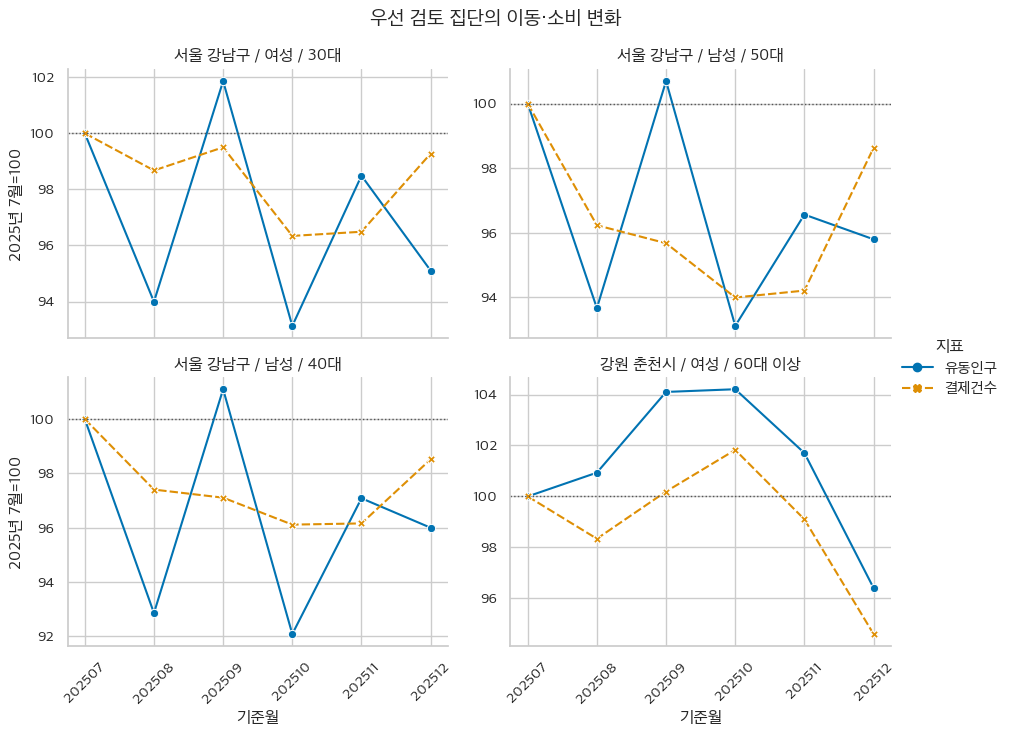

In [18]:
candidate_groups = signal_summary.head(4).index
candidate_frame = combined.set_index(["지역", "성별", "연령대"]).loc[candidate_groups].reset_index()
candidate_long = candidate_frame.melt(
    id_vars=["기준월", "지역", "성별", "연령대"],
    value_vars=["일평균유동인구_7월지수", "결제건수_7월지수"],
    var_name="지표",
    value_name="7월지수",
)
candidate_long["집단"] = (
    candidate_long["지역"] + " / " + candidate_long["성별"] + " / " + candidate_long["연령대"]
)
candidate_long["지표"] = candidate_long["지표"].map(
    {"일평균유동인구_7월지수": "유동인구", "결제건수_7월지수": "결제건수"}
)

chart = sns.relplot(
    data=candidate_long,
    x="기준월",
    y="7월지수",
    hue="지표",
    style="지표",
    col="집단",
    col_wrap=2,
    kind="line",
    markers=True,
    facet_kws={"sharey": False},
    height=3.4,
    aspect=1.35,
)
chart.set_axis_labels("기준월", "2025년 7월=100")
chart.set_titles("{col_name}")
for ax in chart.axes.flat:
    ax.axhline(100, color="#555555", linewidth=1, linestyle=":")
    ax.tick_params(axis="x", rotation=45)
chart.figure.suptitle("우선 검토 집단의 이동·소비 변화", y=1.03)
plt.show()

### 11. 동일 시도·외지 고객 소비 구성

고객 거주지는 시도 단위다. 강남구에서는 `서울`, 춘천시에서는 `강원`을 `동일 시도`로 분류하고 나머지는 `외지`, 결측과 원본의 `정보없음`은 별도 분류한다. 이는 정확한 거주지-사용지 일치가 아니며 강남구·춘천시 주민을 식별하지 않는다.

지역 전체 구성에 더해 성·연령 집단별 외지 결제 비중, 알려진 고객 거주 시도의 정규화 Shannon 다양성, 7월 대비 소비 변화의 거주지 구분별 기여분을 확인한다.

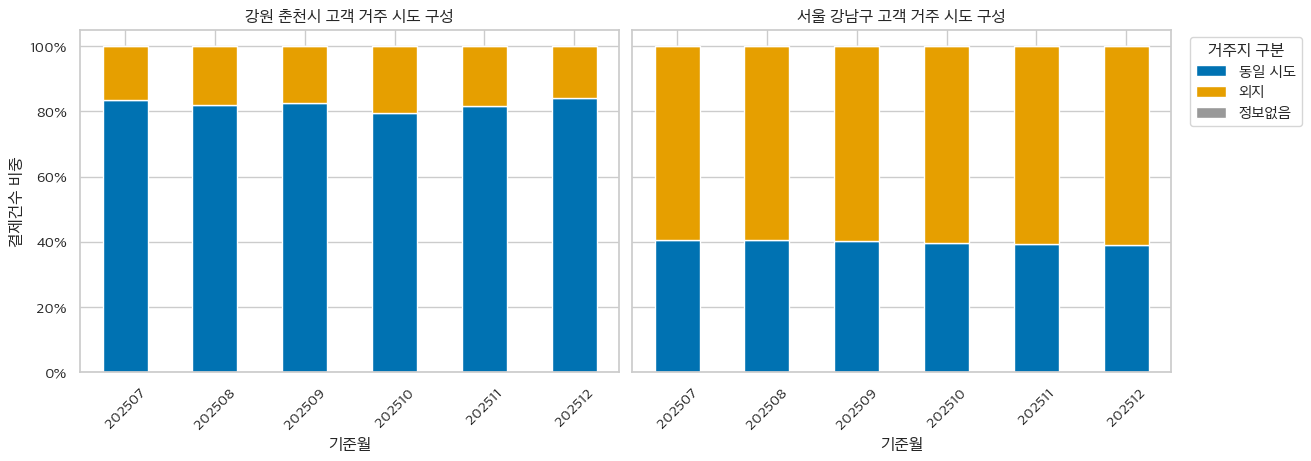

기준월           202507  202508  202509  202510  202511  202512
지역     거주지구분                                                
강원 춘천시 동일 시도  0.8358  0.8187  0.8243  0.7945  0.8167  0.8403
       외지     0.1636  0.1807  0.1752   0.205  0.1828  0.1592
       정보없음   0.0006  0.0006  0.0005  0.0005  0.0005  0.0005
서울 강남구 동일 시도  0.4054  0.4048  0.4035  0.3953  0.3939  0.3909
       외지     0.5941  0.5947  0.5959  0.6041  0.6056  0.6086
       정보없음   0.0006  0.0006  0.0006  0.0006  0.0005  0.0005

In [19]:
residence = (
    pd.concat(residence_parts, ignore_index=True)
    .groupby(
        ["기준월", "MCT_SGG_CD", "SEX_CCD", "연령대", "CLN_SGG_CD"],
        as_index=False,
        observed=True,
        dropna=False,
    )[["결제건수", "결제금액"]]
    .sum()
    .rename(
        columns={
            "MCT_SGG_CD": "지역",
            "SEX_CCD": "성별",
            "CLN_SGG_CD": "고객거주지",
        }
    )
)
residence["고객거주지"] = residence["고객거주지"].fillna("정보없음")
is_unknown = residence["고객거주지"].eq("정보없음")
is_same_province = (
    residence["지역"].eq("서울 강남구") & residence["고객거주지"].eq("서울")
) | (
    residence["지역"].eq("강원 춘천시") & residence["고객거주지"].eq("강원")
)
residence["거주지구분"] = np.select(
    [is_unknown, is_same_province], ["정보없음", "동일 시도"], default="외지"
)

residence_segment = residence.groupby(
    [*segment_keys, "거주지구분"], as_index=False, observed=True
)[["결제건수", "결제금액"]].sum()
for metric in ["결제건수", "결제금액"]:
    residence_segment[f"{metric}비중"] = residence_segment[metric] / residence_segment.groupby(
        segment_keys
    )[metric].transform("sum")

known_residence = residence[~is_unknown].copy()
known_residence["거주시도비중"] = known_residence["결제건수"] / known_residence.groupby(
    segment_keys
)["결제건수"].transform("sum")
known_residence["entropy_part"] = -known_residence["거주시도비중"] * np.log(
    known_residence["거주시도비중"]
)
residence_diversity = known_residence.groupby(segment_keys, as_index=False).agg(
    거주시도수=("고객거주지", "nunique"),
    거주시도_Shannon=("entropy_part", "sum"),
)
residence_diversity["거주시도다양성지수"] = residence_diversity["거주시도_Shannon"] / np.log(
    residence_diversity["거주시도수"]
)

residence_metrics = residence_segment.pivot_table(
    index=segment_keys,
    columns="거주지구분",
    values=["결제건수비중", "결제금액비중"],
).reset_index()
residence_metrics.columns = [
    "_".join(column).strip("_") if isinstance(column, tuple) else column
    for column in residence_metrics.columns
]
residence_metrics = residence_metrics.merge(
    residence_diversity[[*segment_keys, "거주시도수", "거주시도다양성지수"]],
    on=segment_keys,
    validate="one_to_one",
)

assert len(residence_metrics) == 144
assert residence_metrics["거주시도다양성지수"].between(0, 1).all()
assert np.allclose(
    residence_metrics[
        ["결제건수비중_동일 시도", "결제건수비중_외지", "결제건수비중_정보없음"]
    ].sum(axis=1),
    1,
)

residence_share = residence_segment.groupby(
    ["기준월", "지역", "거주지구분"], as_index=False
)[["결제건수", "결제금액"]].sum()
residence_share["결제건수비중"] = residence_share["결제건수"] / residence_share.groupby(
    ["기준월", "지역"]
)["결제건수"].transform("sum")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, constrained_layout=True)
residence_colors = {"동일 시도": "#0072B2", "외지": "#E69F00", "정보없음": "#999999"}
for ax, region in zip(axes, sorted(EXPECTED_REGIONS), strict=True):
    pivot = residence_share[residence_share["지역"] == region].pivot(
        index="기준월", columns="거주지구분", values="결제건수비중"
    )
    pivot[["동일 시도", "외지", "정보없음"]].plot(
        kind="bar",
        stacked=True,
        color=[residence_colors[column] for column in ["동일 시도", "외지", "정보없음"]],
        ax=ax,
    )
    ax.set(title=f"{region} 고객 거주 시도 구성", xlabel="기준월", ylabel="결제건수 비중")
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
    ax.tick_params(axis="x", rotation=45)
    if ax is not axes[-1]:
        ax.get_legend().remove()
axes[-1].legend(title="거주지 구분", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

residence_share.pivot_table(
    index=["지역", "거주지구분"], columns="기준월", values="결제건수비중"
).round(4)

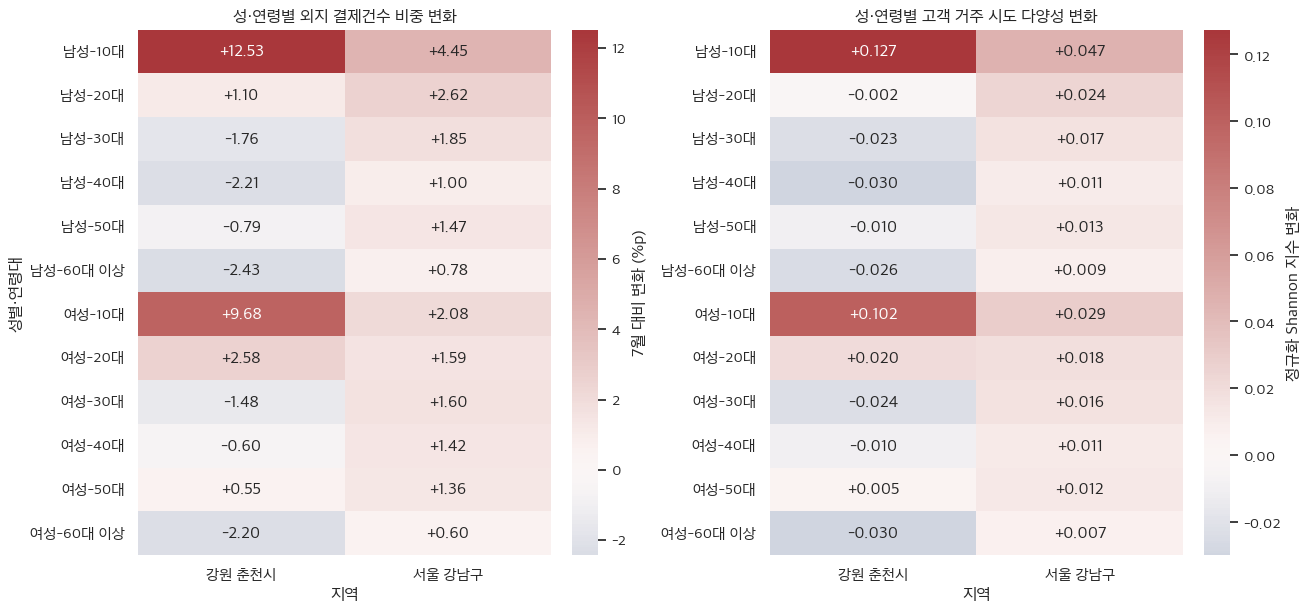

,지역,성별,연령대,유동인구_7월대비(%),결제건수_7월대비(%),외지_결제건수비중_변화(%p),동일시도_결제건수비중_변화(%p),거주시도다양성_변화,탐색조건수,2개월연속동반감소
3,강원 춘천시,여성,60대 이상,-3.596,-5.404,-2.197,2.2,-0.03,5,True
10,강원 춘천시,남성,60대 이상,-4.787,-6.059,-2.427,2.435,-0.026,4,True
8,강원 춘천시,남성,30대,-3.312,-7.231,-1.756,1.754,-0.023,4,True
12,강원 춘천시,남성,50대,-3.168,-6.793,-0.786,0.774,-0.01,4,True
14,강원 춘천시,남성,40대,-2.572,-6.674,-2.207,2.205,-0.03,4,True
15,강원 춘천시,여성,40대,-2.561,-7.012,-0.601,0.601,-0.01,4,True
16,강원 춘천시,여성,30대,-2.084,-6.480,-1.476,1.468,-0.024,4,True
0,서울 강남구,여성,30대,-4.895,-0.723,1.604,-1.6,0.016,3,False
1,서울 강남구,남성,50대,-4.203,-1.372,1.467,-1.465,0.013,3,False
2,서울 강남구,남성,40대,-4.004,-1.484,1.001,-0.995,0.011,3,False


In [20]:
residence_first_last = residence_metrics[
    residence_metrics["기준월"].isin(["202507", "202512"])
].pivot_table(
    index=["지역", "성별", "연령대"],
    columns="기준월",
    values=[
        "결제건수비중_동일 시도",
        "결제건수비중_외지",
        "결제금액비중_외지",
        "거주시도다양성지수",
    ],
)
residence_change = pd.DataFrame(
    {
        "동일시도_결제건수비중_변화(%p)": 100
        * (
            residence_first_last[("결제건수비중_동일 시도", "202512")]
            - residence_first_last[("결제건수비중_동일 시도", "202507")]
        ),
        "외지_결제건수비중_변화(%p)": 100
        * (
            residence_first_last[("결제건수비중_외지", "202512")]
            - residence_first_last[("결제건수비중_외지", "202507")]
        ),
        "외지_결제금액비중_변화(%p)": 100
        * (
            residence_first_last[("결제금액비중_외지", "202512")]
            - residence_first_last[("결제금액비중_외지", "202507")]
        ),
        "거주시도다양성_변화": residence_first_last[("거주시도다양성지수", "202512")]
        - residence_first_last[("거주시도다양성지수", "202507")],
    }
)

outside_heatmap = residence_change["외지_결제건수비중_변화(%p)"].unstack("지역")
residence_diversity_heatmap = residence_change["거주시도다양성_변화"].unstack("지역")
row_order = pd.MultiIndex.from_product(
    [["남성", "여성"], segment_order], names=["성별", "연령대"]
)
outside_heatmap = outside_heatmap.reindex(row_order).astype(float)
residence_diversity_heatmap = residence_diversity_heatmap.reindex(row_order).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
sns.heatmap(
    outside_heatmap,
    annot=True,
    fmt="+.2f",
    center=0,
    cmap="vlag",
    cbar_kws={"label": "7월 대비 변화 (%p)"},
    ax=axes[0],
)
axes[0].set(title="성·연령별 외지 결제건수 비중 변화", xlabel="지역", ylabel="성별·연령대")
sns.heatmap(
    residence_diversity_heatmap,
    annot=True,
    fmt="+.3f",
    center=0,
    cmap="vlag",
    cbar_kws={"label": "정규화 Shannon 지수 변화"},
    ax=axes[1],
)
axes[1].set(title="성·연령별 고객 거주 시도 다양성 변화", xlabel="지역", ylabel="")
plt.show()

residence_signal_summary = signal_summary.reset_index().merge(
    residence_change.reset_index(),
    on=["지역", "성별", "연령대"],
    validate="one_to_one",
)
residence_signal_summary["외지축소_동일시도편중"] = (
    residence_signal_summary["외지_결제건수비중_변화(%p)"].lt(0)
    & residence_signal_summary["동일시도_결제건수비중_변화(%p)"].gt(0)
)
residence_signal_summary["탐색조건수"] = pd.DataFrame(
    {
        "유동감소": residence_signal_summary["유동인구_7월대비(%)"].lt(0),
        "결제감소": residence_signal_summary["결제건수_7월대비(%)"].lt(0),
        "외지비중감소": residence_signal_summary["외지_결제건수비중_변화(%p)"].lt(0),
        "동일시도편중증가": residence_signal_summary[
            "동일시도_결제건수비중_변화(%p)"
        ].gt(0),
        "업종다양성감소": residence_signal_summary["다양성_7월대비"].lt(0),
    }
).sum(axis=1)
residence_signal_summary = residence_signal_summary.sort_values(
    ["탐색조건수", "2개월연속동반감소", "유동인구_7월대비(%)"],
    ascending=[False, False, True],
)
residence_signal_summary[
    [
        "지역",
        "성별",
        "연령대",
        "유동인구_7월대비(%)",
        "결제건수_7월대비(%)",
        "외지_결제건수비중_변화(%p)",
        "동일시도_결제건수비중_변화(%p)",
        "거주시도다양성_변화",
        "탐색조건수",
        "2개월연속동반감소",
    ]
].head(12).round(3)

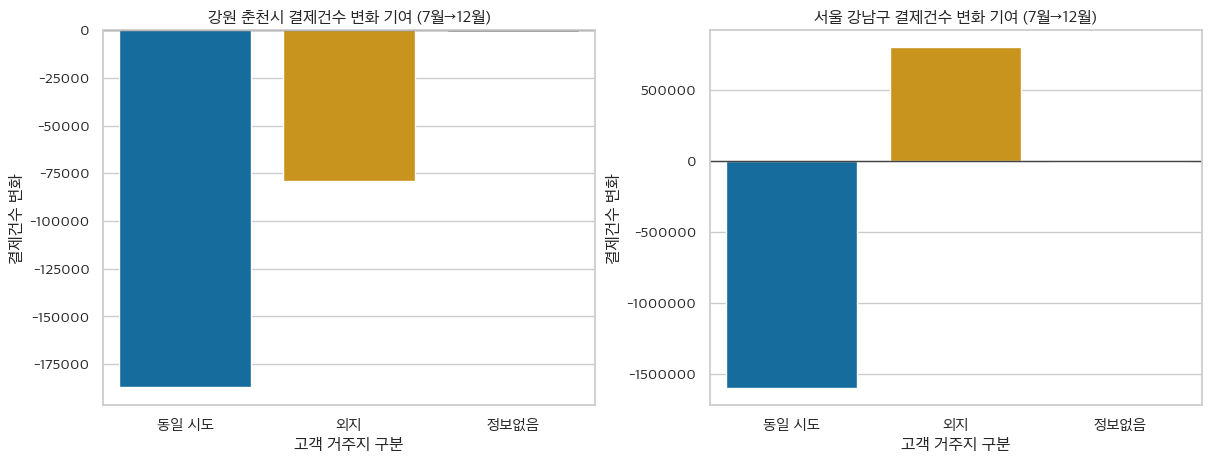

거주지구분,동일 시도,외지,정보없음,전체
지역,,,,
강원 춘천시,-187055.0,-79163.0,-992.0,-267210.0
서울 강남구,-1598874.0,803765.0,-3776.0,-798885.0


In [21]:
region_residence_month = residence_share.pivot_table(
    index=["지역", "거주지구분"], columns="기준월", values="결제건수"
)
region_residence_change = (
    region_residence_month.assign(
        결제건수변화=lambda frame: frame["202512"] - frame["202507"]
    )["결제건수변화"]
    .rename("결제건수변화")
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, region in zip(axes, sorted(EXPECTED_REGIONS), strict=True):
    plot_data = region_residence_change[region_residence_change["지역"] == region]
    sns.barplot(
        data=plot_data,
        x="거주지구분",
        y="결제건수변화",
        hue="거주지구분",
        order=["동일 시도", "외지", "정보없음"],
        palette=residence_colors,
        ax=ax,
        legend=False,
    )
    ax.axhline(0, color="#444444", linewidth=1)
    ax.set(
        title=f"{region} 결제건수 변화 기여 (7월→12월)",
        xlabel="고객 거주지 구분",
        ylabel="결제건수 변화",
    )
    ax.ticklabel_format(axis="y", style="plain")
plt.show()

region_residence_change.pivot(
    index="지역", columns="거주지구분", values="결제건수변화"
).assign(전체=lambda frame: frame.sum(axis=1)).round(0)

### 12. 전체 유동인구의 시간·요일 패턴

성연령·시간대·요일 테이블은 서로 다른 주변 집계이므로 교차하지 않는다. 야간은 00~05시, 주간은 06~17시의 시간당 평균으로 비교하고, 주말/평일은 각 요일 일평균값의 평균 비율로 비교한다. 2025년 12월 원본의 완전 중복 행은 제거한다.

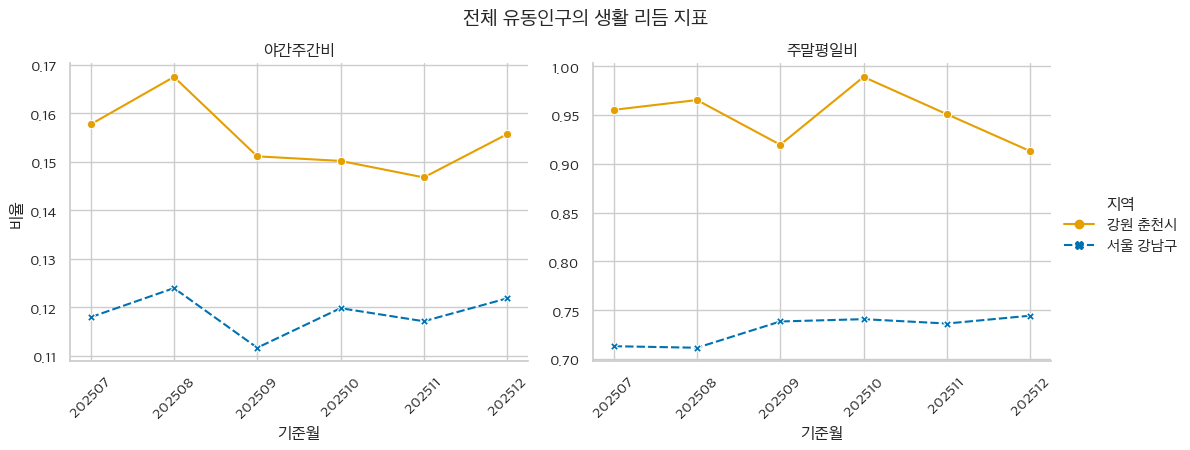

,기준월,지역,야간주간비,주말평일비
0,202507,강원 춘천시,0.1577,0.9553
1,202507,서울 강남구,0.1179,0.7131
2,202508,강원 춘천시,0.1675,0.9653
3,202508,서울 강남구,0.1239,0.7115
4,202509,강원 춘천시,0.1511,0.9195
5,202509,서울 강남구,0.1116,0.7384
6,202510,강원 춘천시,0.1502,0.9890
7,202510,서울 강남구,0.1198,0.7408
8,202511,강원 춘천시,0.1468,0.9508
9,202511,서울 강남구,0.1171,0.7363


In [22]:
time_columns = [f"TMST_{hour:02d}" for hour in range(24)]
weekday_columns = [
    "FLOW_POP_CNT_MON",
    "FLOW_POP_CNT_TUS",
    "FLOW_POP_CNT_WED",
    "FLOW_POP_CNT_THU",
    "FLOW_POP_CNT_FRI",
    "FLOW_POP_CNT_SAT",
    "FLOW_POP_CNT_SUN",
]


def add_inferred_region(frame):
    longitude, _ = transformer.transform(
        frame["X_COORD"].to_numpy(), frame["Y_COORD"].to_numpy()
    )
    return frame.assign(
        지역=np.where(longitude < longitude_cutoff, "서울 강남구", "강원 춘천시")
    )


time_parts = []
weekday_parts = []
for path in SK_FILES:
    if "flow_time" in path.name:
        frame = pd.read_csv(
            path,
            sep="|",
            encoding="utf-8-sig",
            usecols=["STD_YM", "X_COORD", "Y_COORD", *time_columns],
        ).drop_duplicates()
        frame = add_inferred_region(frame)
        grouped = frame.groupby(["STD_YM", "지역"], as_index=False)[time_columns].sum()
        grouped["야간주간비"] = grouped[time_columns[:6]].mean(axis=1) / grouped[
            time_columns[6:18]
        ].mean(axis=1)
        time_parts.append(grouped[["STD_YM", "지역", "야간주간비"]])
    elif "flow_wkdy" in path.name:
        frame = pd.read_csv(
            path,
            sep="|",
            encoding="utf-8-sig",
            usecols=["STD_YM", "X_COORD", "Y_COORD", *weekday_columns],
        ).drop_duplicates()
        frame = add_inferred_region(frame)
        grouped = frame.groupby(["STD_YM", "지역"], as_index=False)[weekday_columns].sum()
        grouped["주말평일비"] = grouped[weekday_columns[-2:]].mean(axis=1) / grouped[
            weekday_columns[:5]
        ].mean(axis=1)
        weekday_parts.append(grouped[["STD_YM", "지역", "주말평일비"]])

rhythm = pd.concat(time_parts).merge(
    pd.concat(weekday_parts), on=["STD_YM", "지역"], validate="one_to_one"
).rename(columns={"STD_YM": "기준월"})
rhythm["기준월"] = rhythm["기준월"].astype(str)

rhythm_long = rhythm.melt(
    id_vars=["기준월", "지역"],
    value_vars=["야간주간비", "주말평일비"],
    var_name="지표",
    value_name="비율",
)
chart = sns.relplot(
    data=rhythm_long,
    x="기준월",
    y="비율",
    hue="지역",
    style="지역",
    col="지표",
    kind="line",
    markers=True,
    facet_kws={"sharey": False},
    height=4,
    aspect=1.35,
    palette=region_colors,
)
chart.set_axis_labels("기준월", "비율")
chart.set_titles("{col_name}")
for ax in chart.axes.flat:
    ax.tick_params(axis="x", rotation=45)
chart.figure.suptitle("전체 유동인구의 생활 리듬 지표", y=1.04)
plt.show()

rhythm.round(4)

### 13. 동기간 외부 취약성 배경값

행정안전부 주민등록 통계에서 제공 데이터와 동일한 2025년 7~12월 월별 자료를 사용한다. 전체 세대 중 1인세대 비율과 10대 이상 1인세대 중 60대 이상 비중을 지역 배경지표로 확인한다. 주민등록상 1인세대가 사회적 고립을 의미하지 않으므로 원인 변수나 정답 레이블로 사용하지 않는다.

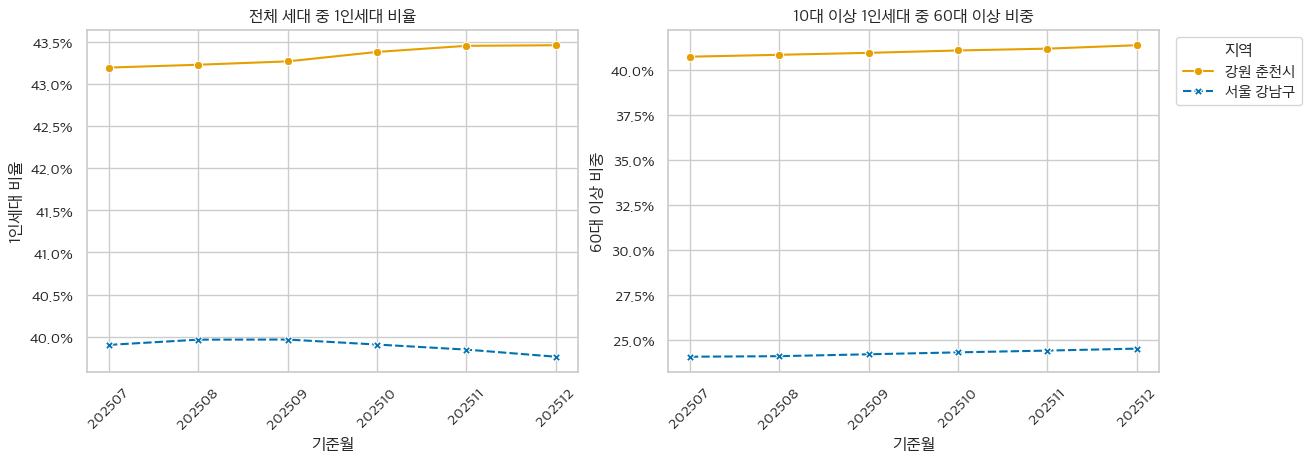

,1인세대비율_7월(%),1인세대비율_12월(%),1인세대비율_변화(%p),60대이상비중_7월(%),60대이상비중_12월(%),60대이상비중_변화(%p)
지역,,,,,,
강원 춘천시,43.198,43.463,0.265,40.743,41.379,0.636
서울 강남구,39.902,39.761,-0.141,24.064,24.512,0.449


In [23]:
resident_dir = RAW_DIR / "reference_data" / "행정안전부_주민등록_거주통계"
household_file = resident_dir / "202507_202512_행정동별_세대원수별_세대수.csv"
single_age_file = resident_dir / "202507_202512_행정동별_성연령별_1인세대수.csv"

household = pd.read_csv(household_file, encoding="cp949", dtype="string")
single_age = pd.read_csv(single_age_file, encoding="cp949", dtype="string")
district_pattern = r"강남구 \(|춘천시 \("
household = household[household["행정구역"].str.contains(district_pattern, regex=True)].copy()
single_age = single_age[single_age["행정구역"].str.contains(district_pattern, regex=True)].copy()

for frame in [household, single_age]:
    frame["지역"] = np.where(
        frame["행정구역"].str.contains("강남구"), "서울 강남구", "강원 춘천시"
    )


def resident_number(value):
    return int(value.replace(",", ""))


resident_rows = []
old_age_columns = ["60~69세", "70~79세", "80~89세", "90~99세", "100세 이상"]
for month in range(7, 13):
    month_label = f"2025년{month:02d}월"
    기준월 = f"2025{month:02d}"
    for _, household_row in household.iterrows():
        지역 = household_row["지역"]
        age_row = single_age[single_age["지역"] == 지역].iloc[0]
        전체세대 = resident_number(household_row[f"{month_label}_전체세대"])
        일인세대 = resident_number(household_row[f"{month_label}_1인세대"])
        일인세대_총수 = resident_number(age_row[f"{month_label}_계_총세대수"])
        일인세대_10대이상 = resident_number(age_row[f"{month_label}_계_연령구간세대수"]) - resident_number(
            age_row[f"{month_label}_계_0~9세"]
        )
        일인세대_60대이상 = sum(
            resident_number(age_row[f"{month_label}_계_{age}"]) for age in old_age_columns
        )
        assert 일인세대 == 일인세대_총수
        resident_rows.append(
            {
                "기준월": 기준월,
                "지역": 지역,
                "전체세대": 전체세대,
                "1인세대": 일인세대,
                "1인세대비율": 일인세대 / 전체세대,
                "1인세대_60대이상비중": 일인세대_60대이상 / 일인세대_10대이상,
            }
        )

resident_monthly = pd.DataFrame(resident_rows).sort_values(["지역", "기준월"])
assert len(resident_monthly) == 12
assert not resident_monthly.isna().any().any()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
sns.lineplot(
    data=resident_monthly,
    x="기준월",
    y="1인세대비율",
    hue="지역",
    style="지역",
    markers=True,
    palette=region_colors,
    ax=axes[0],
)
axes[0].set(title="전체 세대 중 1인세대 비율", xlabel="기준월", ylabel="1인세대 비율")
axes[0].yaxis.set_major_formatter(lambda value, _: f"{value:.1%}")
axes[0].tick_params(axis="x", rotation=45)
axes[0].get_legend().remove()
sns.lineplot(
    data=resident_monthly,
    x="기준월",
    y="1인세대_60대이상비중",
    hue="지역",
    style="지역",
    markers=True,
    palette=region_colors,
    ax=axes[1],
)
axes[1].set(
    title="10대 이상 1인세대 중 60대 이상 비중",
    xlabel="기준월",
    ylabel="60대 이상 비중",
)
axes[1].yaxis.set_major_formatter(lambda value, _: f"{value:.1%}")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(title="지역", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

resident_change = resident_monthly.pivot(
    index="지역", columns="기준월", values=["1인세대비율", "1인세대_60대이상비중"]
)
pd.DataFrame(
    {
        "1인세대비율_7월(%)": 100 * resident_change[("1인세대비율", "202507")],
        "1인세대비율_12월(%)": 100 * resident_change[("1인세대비율", "202512")],
        "1인세대비율_변화(%p)": 100
        * (
            resident_change[("1인세대비율", "202512")]
            - resident_change[("1인세대비율", "202507")]
        ),
        "60대이상비중_7월(%)": 100
        * resident_change[("1인세대_60대이상비중", "202507")],
        "60대이상비중_12월(%)": 100
        * resident_change[("1인세대_60대이상비중", "202512")],
        "60대이상비중_변화(%p)": 100
        * (
            resident_change[("1인세대_60대이상비중", "202512")]
            - resident_change[("1인세대_60대이상비중", "202507")]
        ),
    }
).round(3)

## Takeaways

1. **우선 검토 후보는 춘천시 고령층이다.** 60대 이상 유동인구는 7월 454,788명에서 12월 435,789명으로 4.18% 감소했고, 지역 내 비중도 25.32%에서 24.56%로 0.76%p 낮아졌다. 같은 기간 결제건수는 5.78% 감소했다.
2. **세 지표가 항상 같은 방향은 아니다.** 춘천시 60대 이상은 이동·소비가 함께 감소했지만 업종 다양성 변화는 성별에 따라 달랐다. 따라서 이동·소비 감소만으로 활동 다양성까지 위축됐다고 주장하지 않는다.
3. **춘천 고령층의 소비권역도 좁아진 방향이다.** 7월 대비 12월 외지 결제건수 비중은 춘천시 60대 이상에서 남성 2.43%p, 여성 2.20%p 감소했고, 고객 거주 시도 다양성도 각각 0.026, 0.030 낮아졌다. 춘천시 전체 결제 감소분 267,210건 중 동일 시도 감소가 187,055건, 외지 감소가 79,163건이었다. 반면 강남구는 모든 성·연령 집단에서 외지 비중과 다양성이 증가했다. 이는 지역별 소비권역 변화이며, 시도 단위 고객 거주지로 개인의 활동 반경이나 해당 시군구 주민 여부를 판단할 수 없다.
4. **전체 생활 리듬은 지역별로 달랐다.** 주말/평일 유동 비율은 춘천시에서 0.955→0.913으로 낮아지고 강남구에서 0.713→0.744로 높아졌다. 연령·성별과 시간·요일을 교차할 수 없어 고령층 변화와 직접 연결하지 않는다.
5. **동기간 주민등록 통계는 춘천의 고령 1인세대 취약성 맥락을 보강한다.** 1인세대 비율은 춘천시에서 43.20%→43.46%, 강남구에서 39.90%→39.76%였고, 10대 이상 1인세대 중 60대 이상 비중은 춘천시에서 40.74%→41.38%, 강남구에서 24.06%→24.51%였다. 주민등록상 1인세대는 사회적 고립과 동일하지 않으며 동시 변화만으로 인과관계를 주장하지 않는다.

현재 근거로 가능한 결론은 “춘천시 고령층에서 이동·소비의 동반 위축과 높은 고령 1인세대 배경이 함께 관측됐다”까지다. 개인의 고립 여부를 직접 의미하지 않으며 계절, 날씨, 인구 변화, 카드 이용 변화 등 대안 설명을 추가로 검증해야 한다.